#import library

In [8]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense,Flatten

#mnist dataset

In [12]:
(x_train,y_train),(x_test,y_test)=keras.datasets.mnist.load_data()

In [13]:
x_test.shape

(10000, 28, 28)

In [14]:
x_train.shape

(60000, 28, 28)

In [20]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

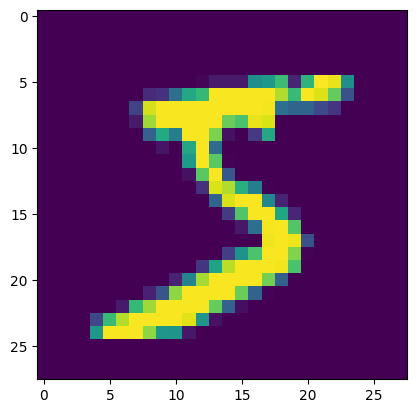

In [22]:
import matplotlib.pyplot as plt
plt.imshow(x_train[0])

#normalization

In [23]:
x_train=x_train/255
x_test=x_test/255

In [24]:
x_train[0]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.    

In [27]:
from tensorflow.keras.layers import Input

model = Sequential([
    Input(shape=(28, 28)), # Define input shape explicitly with an Input layer
    Flatten(),
    Dense(128, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

In [28]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,938 (409.91 KB)

 Trainable params: 104,938 (409.91 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
model.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

In [31]:
history=model.fit(x_train,y_train,epochs=5,validation_split=0.2)

Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9184 - loss: 0.2847 - val_accuracy: 0.9506 - val_loss: 0.1690
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9631 - loss: 0.1206 - val_accuracy: 0.9647 - val_loss: 0.1222
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9751 - loss: 0.0830 - val_accuracy: 0.9724 - val_loss: 0.0962
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9807 - loss: 0.0618 - val_accuracy: 0.9726 - val_loss: 0.0966
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9850 - loss: 0.0489 - val_accuracy: 0.9723 - val_loss: 0.0962


In [32]:
y_prob=model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [34]:
y_pred=y_prob.argmax(axis=1)

In [36]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.974

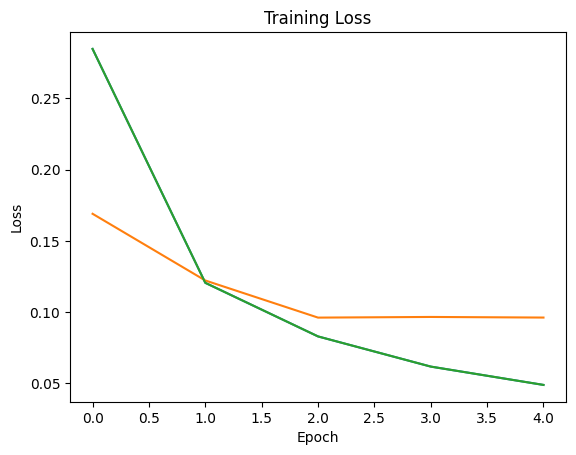

In [41]:
import matplotlib.pyplot as plt
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

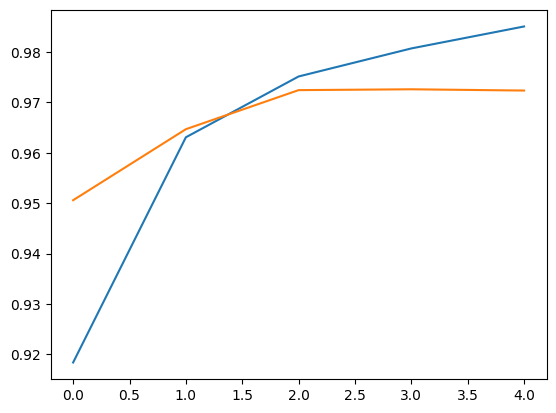

In [43]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

#prediction system

In [50]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
from keras.utils import load_img,img_to_array
from PIL import Image

#load the train model

In [52]:
model.save("mnist_model.h5")
model=load_model("mnist_model.h5")

#define the prediction model

In [60]:
def predict_and_display_with_class_name(image_path, model):
    # Load and preprocess the image
    image = Image.open(image_path).convert("L") # Convert to grayscale
    image = image.resize((28, 28)) # Resize to 28x28 pixels
    image_array = np.array(image) # Convert to numpy array
    image_array = image_array / 255.0 # Normalize pixel values to 0-1
    image_array = image_array.reshape(1, 28, 28) # Reshape for model input (add batch dimension)

    # Make prediction
    predictions = model.predict(image_array)
    predicted_class = np.argmax(predictions[0])
    confidence = np.max(predictions[0]) * 100

    # Display the image and prediction
    plt.imshow(image_array.reshape(28, 28), cmap='gray')
    plt.title(f"Predicted: {predicted_class} (Confidence: {confidence:.2f}%)")
    plt.axis('off')
    plt.show()

    return predicted_class, confidence

#load the image

Created a dummy image at: dummy_digit.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step


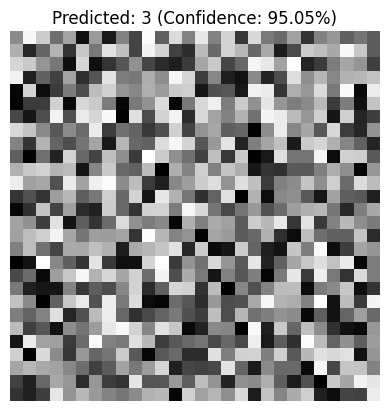

Removed dummy image: dummy_digit.png


In [61]:
# Example usage:
# First, you need to have an image file. For now, let's create a dummy one or point to a non-existent path.
# For MNIST, you might generate an image or use a test image.

# Let's create a dummy image for demonstration purposes.
from PIL import Image
import numpy as np

dummy_image_path = 'dummy_digit.png'
dummy_image_array = np.random.randint(0, 256, size=(28, 28), dtype=np.uint8)
dummy_image = Image.fromarray(dummy_image_array)
dummy_image.save(dummy_image_path)

print(f"Created a dummy image at: {dummy_image_path}")

# Now call the function with the dummy image path
predict_and_display_with_class_name(dummy_image_path, model)

# You can also clean up the dummy file if no longer needed
import os
os.remove(dummy_image_path)
print(f"Removed dummy image: {dummy_image_path}")